# Part 1: Finite difference solution of the Black-Scholes PDE

**Aim of this part**

In this notebook we price a European call and a cash-or-nothing digital call by solving the Black-Scholes PDE on a grid. We first transform the PDE into the heat equation $u_\tau = u_{xx}$, which is the same equation as exercise R4.1(a) up to a constant, and then solve it with the explicit, implicit and Crank-Nicolson finite difference schemes from Sauer Section 8.1. Because both options have closed form prices and Greeks, every error in this notebook is a true error measured against the exact answer rather than an estimate. The main questions are when each scheme is stable, how fast each one converges, and what goes wrong near the strike, where the payoff has a kink (call) or a jump (digital).

In [1]:
import sys
import time
sys.path.append("..")  # so that the pricing folder can be imported

import numpy as np
import matplotlib.pyplot as plt

from pricing import black_scholes as bs
from pricing import pde
from pricing.plot_style import use_project_style, COLOURS, MARKERS, INK, GREY

use_project_style()

# Model parameters used throughout the project
S0, K, r, sigma, T = 100.0, 100.0, 0.05, 0.2, 1.0
print(f"Exact call price    {bs.call_price(S0, K, r, sigma, T):.6f}")
print(f"Exact digital price {bs.digital_price(S0, K, r, sigma, T):.6f}")

Exact call price    10.450584
Exact digital price 0.532325


**The Black-Scholes PDE**

Let $V(S,t)$ be the value of a European option on a stock with price $S$ at time $t$, with expiry $T$, strike $K$, risk free rate $r$ and volatility $\sigma$. Then $V$ satisfies

$$\frac{\partial V}{\partial t} + \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} + rS\frac{\partial V}{\partial S} - rV = 0, \qquad V(S,T) = f(S),$$

where $f$ is the payoff. For a call $f(S) = \max(S-K, 0)$, and for the digital call $f(S) = 1$ if $S > K$ and $0$ otherwise. The condition is given at the final time $T$, so the problem is solved backwards in time from expiry. Compared with the heat equation from R4.1(a) there are two extra difficulties: the coefficients $S^2$ and $S$ vary across the grid, and there are first derivative (drift) and zeroth derivative (discounting) terms. Both are removed by a change of variables, which we derive next following Wilmott, Howison and Dewynne (1995).

**Step one: logarithmic variables**

We set $S = Ke^x$, $t = T - 2\tau/\sigma^2$ and $V(S,t) = K\,v(x,\tau)$, so $x = \ln(S/K)$ measures how far the stock is from the strike and $\tau = \frac{1}{2}\sigma^2(T-t)$ is a rescaled time to expiry. By the chain rule, using $\partial x/\partial S = 1/S$ and $\partial \tau/\partial t = -\sigma^2/2$,

$$\frac{\partial V}{\partial t} = -\frac{\sigma^2}{2} K v_\tau, \qquad S\frac{\partial V}{\partial S} = K v_x, \qquad S^2\frac{\partial^2 V}{\partial S^2} = K\left(v_{xx} - v_x\right).$$

The last identity comes from differentiating $\partial V/\partial S = (K/S)v_x$ once more, which gives $\partial^2 V/\partial S^2 = (K/S^2)(v_{xx} - v_x)$. Substituting into the PDE and dividing by $\frac{1}{2}\sigma^2 K$ gives

$$v_\tau = v_{xx} + (k-1)v_x - kv, \qquad k = \frac{2r}{\sigma^2}.$$

The coefficients are now constant, but the equation still has a drift term $(k-1)v_x$ and a discount term $-kv$.

**Step two: removing the drift and discount terms**

We now look for a solution of the form $v = e^{\alpha x + \beta\tau}u(x,\tau)$ and choose the constants $\alpha$ and $\beta$ to cancel the unwanted terms. Differentiating,

$$v_\tau = e^{\alpha x + \beta \tau}(\beta u + u_\tau), \quad v_x = e^{\alpha x + \beta \tau}(\alpha u + u_x), \quad v_{xx} = e^{\alpha x + \beta \tau}(\alpha^2 u + 2\alpha u_x + u_{xx}).$$

Substituting and cancelling the common exponential factor,

$$u_\tau = u_{xx} + \left(2\alpha + k - 1\right)u_x + \left(\alpha^2 + (k-1)\alpha - k - \beta\right)u.$$

The $u_x$ term vanishes if $\alpha = -\frac{1}{2}(k-1)$, and then the $u$ term vanishes if $\beta = \alpha^2 + (k-1)\alpha - k = -\frac{1}{4}(k+1)^2$. What is left is the heat equation

$$u_\tau = u_{xx}.$$

So the Black-Scholes PDE, run backwards from expiry, is the heat equation run forwards in $\tau$. The payoff plays the role of the initial temperature profile.

**Initial and boundary conditions in the new variables**

Undoing the substitutions, $u = (V/K)e^{-\alpha x - \beta\tau}$. At expiry $\tau = 0$, so the initial condition is $u(x,0) = e^{-\alpha x} f(Ke^x)/K$. For the call this is

$$u(x,0) = \max\left(e^{\frac{1}{2}(k+1)x} - e^{\frac{1}{2}(k-1)x},\ 0\right),$$

and for the digital it is $e^{\frac{1}{2}(k-1)x}/K$ for $x > 0$ and zero for $x < 0$. The real problem lives on $-\infty < x < \infty$, so we truncate to $[-x_{\max}, x_{\max}]$ and impose the known behaviour of the option at the ends. Far below the strike both options are worthless, so $V = 0$. Far above the strike the call behaves like $S - Ke^{-r(T-t)}$ and the digital is certain to pay out, so it is worth $e^{-r(T-t)}$. These values of $V$ are converted to values of $u$ with the same formula. We use $x_{\max} = 2$, which covers stock prices from about 13.5 to 739. A quick check (not shown) with a fixed grid spacing gave identical prices at the strike to about $10^{-12}$ for every $x_{\max} \geq 1$, so the truncation error is negligible next to the discretisation error we study below.

**A note on the size of the transformed numbers**

The factor $e^{\alpha x + \beta\tau}$ can be very large or very small, so it is fair to ask whether the transform causes rounding trouble (Module 1.1). Multiplying by a large number is harmless in floating point, because a product keeps its relative error, unlike the subtraction of nearly equal numbers discussed in Section 1.1.1. The real risk is overflow (Section 1.1.3). The largest exponent on the grid is about $\frac{1}{2}(k+1)x_{\max}$ in the initial condition, and $\frac{1}{2}(k-1)x_{\max}$ in the upper boundary condition. A double overflows once an exponent passes about 709, and since $k = 2r/\sigma^2$ this only happens for very small volatilities. The cell below shows the exponents for a range of $\sigma$, and confirms that for $\sigma = 1\%$ the transformed problem overflows, so that the linear solver is handed infinite values and stops. For realistic volatilities the transform is completely safe. A more important limitation is that the transform needs $r$ and $\sigma$ to be constant. With a volatility that depends on $S$ or $t$ we would have to solve the $v$ equation, drift term included, directly.

In [2]:
k = 2 * r / sigma**2
alpha = -0.5 * (k - 1)
beta = -0.25 * (k + 1) ** 2
print(f"For sigma = {sigma}:  k = {k:.3f},  alpha = {alpha:.3f},  beta = {beta:.4f}")
print()

x_max = 2.0
for vol in [0.4, 0.2, 0.1, 0.05, 0.02, 0.01]:
    k_vol = 2 * r / vol**2
    print(f"sigma = {vol:5.2f}   k = {k_vol:8.1f}   largest exponent about {(k_vol + 1) * x_max / 2:8.1f}")

# Pricing with sigma = 1% overflows. The overflow warnings are switched off to keep the
# output tidy, and scipy's banded solver then refuses the infinite values.
print()
try:
    with np.errstate(over="ignore", invalid="ignore"):
        pde.price_heat_grid("call", K, r, 0.01, T, 2.0, 400, 40, 0.5, n_rannacher=2)
except ValueError as error:
    print("Pricing with sigma = 1% fails:", error)

For sigma = 0.2:  k = 2.500,  alpha = -0.750,  beta = -3.0625

sigma =  0.40   k =      0.6   largest exponent about      1.6
sigma =  0.20   k =      2.5   largest exponent about      3.5
sigma =  0.10   k =     10.0   largest exponent about     11.0
sigma =  0.05   k =     40.0   largest exponent about     41.0
sigma =  0.02   k =    250.0   largest exponent about    251.0
sigma =  0.01   k =   1000.0   largest exponent about   1001.0

Pricing with sigma = 1% fails: array must not contain infs or NaNs


**The theta scheme**

We put the heat equation on a uniform grid $x_j = -x_{\max} + j\Delta x$ for $j = 0, \dots, N_x$ and $\tau_n = n\Delta\tau$ for $n = 0, \dots, N_\tau$, write $u_j^n \approx u(x_j, \tau_n)$, and define the mesh ratio $\lambda = \Delta\tau/\Delta x^2$. Replacing $u_{xx}$ by the second difference from Section 1.3.6, and taking a weighted average of the two time levels with weight $\theta$, gives

$$u_j^{n+1} - u_j^n = \lambda\theta\left(u_{j-1}^{n+1} - 2u_j^{n+1} + u_{j+1}^{n+1}\right) + \lambda(1-\theta)\left(u_{j-1}^{n} - 2u_j^{n} + u_{j+1}^{n}\right).$$

With $\theta = 0$ this is the explicit forward difference method (Sauer Program 8.1), where each new value comes straight from the old ones. With $\theta = 1$ it is the implicit backward difference method, and with $\theta = \frac{1}{2}$ it is Crank-Nicolson. The local truncation error is $O(\Delta\tau + \Delta x^2)$ for $\theta \neq \frac{1}{2}$ and $O(\Delta\tau^2 + \Delta x^2)$ for Crank-Nicolson. This is the same reason the central difference beats the one sided differences in Section 1.3.3: averaging the forward and backward formulas cancels the first order error term. For $\theta > 0$ each time step needs the solution of a tridiagonal linear system. A tridiagonal system is a banded matrix (Section 2.3.8), so we solve it with `scipy.linalg.solve_banded`, which takes $O(N_x)$ operations per step rather than the $O(N_x^3)$ of dense Gaussian elimination. The code is `heat_theta_scheme` in `pricing/pde.py`.

Crank-Nicolson has a well known weakness with non-smooth initial data, described further below. The standard fix, due to Rannacher (1984), is to take the first few time steps with the fully implicit scheme and only then switch to Crank-Nicolson. In the code this is the argument `n_rannacher`.

**Checking the solver against the closed form**

Before studying the schemes we check that the whole pipeline is correct: building the grid, transforming the payoff and boundary values, time stepping, and transforming back. The cell below uses Crank-Nicolson with four Rannacher steps (the reason for four, rather than the usual two, appears later) on 1600 space intervals and 160 time steps.

Call    at S0: grid 10.450362  exact 10.450584  error 2.21e-04
Digital at S0: grid 0.532323  exact 0.532325  error 2.09e-06


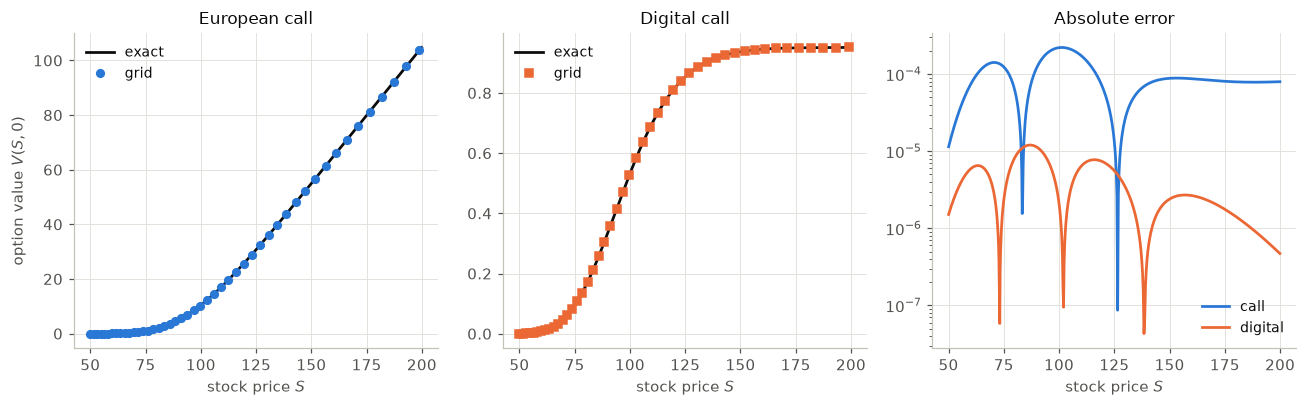

In [3]:
n_x, n_tau = 1600, 160
S, V_call = pde.price_heat_grid("call", K, r, sigma, T, 2.0, n_x, n_tau, 0.5, n_rannacher=4)
S, V_dig = pde.price_heat_grid("digital", K, r, sigma, T, 2.0, n_x, n_tau, 0.5, n_rannacher=4)
exact_call = bs.call_price(S, K, r, sigma, T)
exact_dig = bs.digital_price(S, K, r, sigma, T)

i0 = n_x // 2  # the node with S = K = S0
print(f"Call    at S0: grid {V_call[i0]:.6f}  exact {exact_call[i0]:.6f}  error {abs(V_call[i0] - exact_call[i0]):.2e}")
print(f"Digital at S0: grid {V_dig[i0]:.6f}  exact {exact_dig[i0]:.6f}  error {abs(V_dig[i0] - exact_dig[i0]):.2e}")

window = (S > 50) & (S < 200)
every = 12  # only draw every 12th grid point so the markers are visible

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].plot(S[window], exact_call[window], color=INK, label="exact")
axes[0].plot(S[window][::every], V_call[window][::every], "o", color=COLOURS[0], label="grid")
axes[0].set_title("European call")
axes[0].set_xlabel("stock price $S$")
axes[0].set_ylabel("option value $V(S, 0)$")
axes[0].legend()

axes[1].plot(S[window], exact_dig[window], color=INK, label="exact")
axes[1].plot(S[window][::every], V_dig[window][::every], "s", color=COLOURS[1], label="grid")
axes[1].set_title("Digital call")
axes[1].set_xlabel("stock price $S$")
axes[1].legend()

axes[2].semilogy(S[window], np.abs(V_call - exact_call)[window], color=COLOURS[0], label="call")
axes[2].semilogy(S[window], np.abs(V_dig - exact_dig)[window], color=COLOURS[1], label="digital")
axes[2].set_title("Absolute error")
axes[2].set_xlabel("stock price $S$")
axes[2].legend()

fig.tight_layout()
fig.savefig("../figures/01_solver_check.png")
plt.show()

The grid prices sit on top of the exact curves. The errors are at most about $2 \times 10^{-4}$ for the call and $10^{-5}$ for the digital across the whole range, so the transform, the boundary conditions and the back transform are all working. The call error peaks at the strike, where its payoff has the kink, while the digital error is spread over the region where its price changes fastest. The dips to very small values are just points where the error changes sign.

**Stability of the explicit scheme**

For the explicit scheme a von Neumann analysis (Sauer Section 8.1) looks at a single Fourier mode $u_j^n = g^n e^{i j \xi\Delta x}$. Substituting into the scheme with $\theta = 0$ gives the amplification factor

$$g = 1 - 4\lambda\sin^2\left(\tfrac{1}{2}\xi\Delta x\right).$$

The scheme is stable when $|g| \le 1$ for every mode, which holds exactly when $\lambda \le \frac{1}{2}$. The most dangerous mode is the sawtooth $\xi\Delta x = \pi$, with $g = 1 - 4\lambda$. In calendar time $\Delta t = 2\Delta\tau/\sigma^2$, so the condition reads $\Delta t \le \Delta x^2/\sigma^2$. This is exactly the behaviour asked about in exercise R4.1(a). There the equation is $u_t = 2u_{xx}$ with $h = 0.1$, so stability needs $2k/h^2 \le \frac{1}{2}$, that is $k \le 0.0025$, which is why the solution blows up for $k > 0.003$. The cell below runs the explicit scheme on 200 intervals just below and just above $\lambda = \frac{1}{2}$.

lambda = 0.4808  (104 steps)   largest error on the grid = 8.165e-03
lambda = 0.5208  (96 steps)   largest error on the grid = 4.286e+01


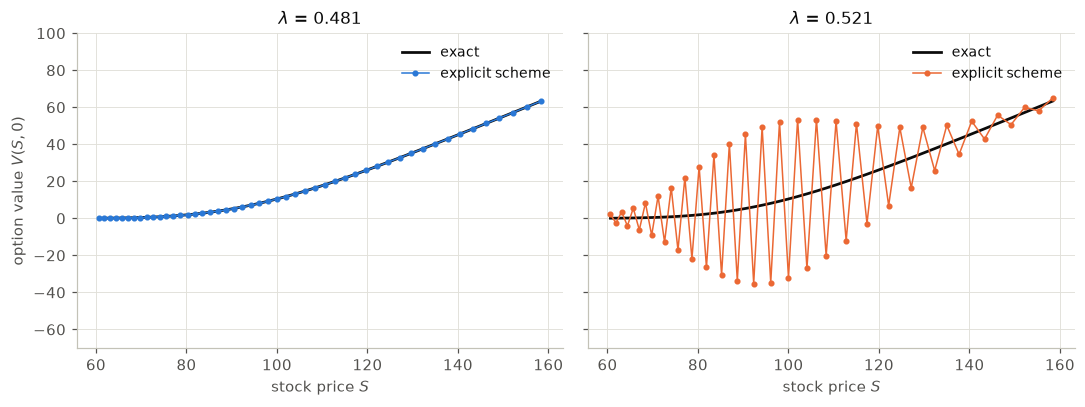

In [4]:
n_x, x_max = 200, 2.0
dx = 2 * x_max / n_x
tau_max = 0.5 * sigma**2 * T

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, lam_target, colour in zip(axes, [0.48, 0.52], [COLOURS[0], COLOURS[1]]):
    n_tau = int(round(tau_max / (lam_target * dx**2)))
    lam = (tau_max / n_tau) / dx**2
    S, V = pde.price_heat_grid("call", K, r, sigma, T, x_max, n_x, n_tau, 0.0)
    max_error = np.max(np.abs(V - bs.call_price(S, K, r, sigma, T)))
    print(f"lambda = {lam:.4f}  ({n_tau} steps)   largest error on the grid = {max_error:.3e}")

    window = (S > 60) & (S < 160)
    ax.plot(S[window], bs.call_price(S[window], K, r, sigma, T), color=INK, label="exact")
    ax.plot(S[window], V[window], "o-", color=colour, markersize=3, linewidth=1, label="explicit scheme")
    ax.set_title(rf"$\lambda$ = {lam:.3f}")
    ax.set_xlabel("stock price $S$")
    ax.set_ylim(-70, 100)
    ax.legend()
axes[0].set_ylabel("option value $V(S, 0)$")
fig.tight_layout()
fig.savefig("../figures/01_explicit_stability.png")
plt.show()

Just below the limit the explicit scheme is accurate. Just above it the sawtooth mode, which is excited by the kink in the payoff, grows by a factor of about $|1 - 4\lambda| \approx 1.08$ per step, and after roughly a hundred steps it swamps the solution. This is the same failure as in R4.1(a).

**Why the log transform matters for stability**

The heat equation coordinates are not just tidier, they also make the stability limit independent of the size of the grid. In the original variable $S$ on a grid $S_j = j\Delta S$, central differences give the explicit update $V_j^{\text{new}} = a_jV_{j-1} + b_jV_j + c_jV_{j+1}$ (see `price_call_explicit_S`), with

$$b_j = 1 - \Delta t\left(\sigma^2 j^2 + r\right).$$

The diffusion coefficient $\frac{1}{2}\sigma^2S^2$ grows with $S$, so the binding constraint is at the top of the grid, and keeping $b_j \ge 0$ there needs roughly $\Delta t \le 1/(\sigma^2 N_S^2 + r)$ with $N_S = S_{\max}/\Delta S$. Doubling $S_{\max}$ at a fixed $\Delta S$ therefore cuts the allowed time step by four. In log coordinates the diffusion coefficient is constant, so the limit $\lambda \le \frac{1}{2}$ does not care how far the grid extends. Below we find the smallest stable number of time steps by bisection, for several grid sizes in each coordinate system. To keep the comparison fair we use $\Delta S = 1$ and $\Delta x = 0.01$, which give the same resolution near the strike, since $\Delta S/S = 0.01$ at $S = 100$.

Explicit scheme in the S variable, dS = 1
  S_max =  200   smallest stable n_t =   1479   dt = 6.76e-04


  S_max =  300   smallest stable n_t =   3400   dt = 2.94e-04


  S_max =  400   smallest stable n_t =   6112   dt = 1.64e-04


  S_max =  600   smallest stable n_t =  13915   dt = 7.19e-05


  S_max =  800   smallest stable n_t =  24894   dt = 4.02e-05
Explicit scheme in the x variable, dx = 0.01
  S_max =    272   smallest stable n_tau = 394   lambda = 0.508   dt = 2.54e-03
  S_max =    739   smallest stable n_tau = 393   lambda = 0.509   dt = 2.54e-03
  S_max =   2009   smallest stable n_tau = 393   lambda = 0.509   dt = 2.54e-03
  S_max =   5460   smallest stable n_tau = 392   lambda = 0.510   dt = 2.55e-03


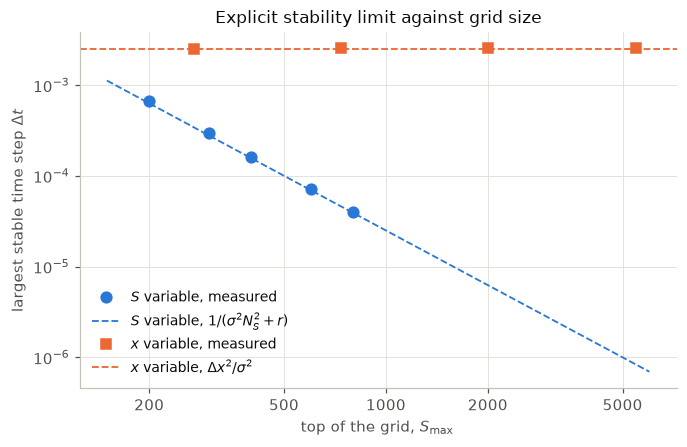

In [5]:
def blew_up(V, scale):
    # Treat the run as unstable if it produced infinities or values far above any sensible price.
    return (not np.all(np.isfinite(V))) or np.max(np.abs(V)) > 10 * scale


def smallest_stable_steps(run, lo, hi, scale):
    # Bisection on the number of time steps: run(lo) blows up and run(hi) is stable.
    while hi - lo > 1:
        mid = (lo + hi) // 2
        with np.errstate(over="ignore", invalid="ignore"):  # unstable runs overflow, which is expected
            V = run(mid)
        if blew_up(V, scale):
            lo = mid
        else:
            hi = mid
    return hi


print("Explicit scheme in the S variable, dS = 1")
S_max_values = [200, 300, 400, 600, 800]
dt_S = []
for S_max in S_max_values:
    n_S = S_max
    theory_steps = int(T * (sigma**2 * (n_S - 1) ** 2 + r))
    run = lambda n_t: pde.price_call_explicit_S(K, r, sigma, T, S_max, n_S, n_t)[1]
    steps = smallest_stable_steps(run, theory_steps // 2, 2 * theory_steps, S_max)
    dt_S.append(T / steps)
    print(f"  S_max = {S_max:4d}   smallest stable n_t = {steps:6d}   dt = {T / steps:.2e}")

print("Explicit scheme in the x variable, dx = 0.01")
x_max_values = [1.0, 2.0, 3.0, 4.0]
dt_x = []
for x_max in x_max_values:
    n_x = int(round(2 * x_max / 0.01))
    run = lambda n_tau: pde.price_heat_grid("call", K, r, sigma, T, x_max, n_x, n_tau, 0.0)[1]
    steps = smallest_stable_steps(run, 100, 1000, K * np.exp(x_max))
    dtau = 0.5 * sigma**2 * T / steps
    dt_x.append(2 * dtau / sigma**2)
    print(f"  S_max = {K * np.exp(x_max):6.0f}   smallest stable n_tau = {steps}   lambda = {dtau / 0.01**2:.3f}   dt = {2 * dtau / sigma**2:.2e}")

S_line = np.linspace(150, 6000, 200)
fig, ax = plt.subplots()
ax.loglog(S_max_values, dt_S, "o", color=COLOURS[0], markersize=7, label="$S$ variable, measured")
ax.loglog(S_line, T / (T * (sigma**2 * (S_line - 1) ** 2 + r)), "--", color=COLOURS[0], linewidth=1.2, label=r"$S$ variable, $1/(\sigma^2 N_S^2 + r)$")
ax.loglog(K * np.exp(np.array(x_max_values)), dt_x, "s", color=COLOURS[1], markersize=7, label="$x$ variable, measured")
ax.axhline(0.01**2 / sigma**2, linestyle="--", color=COLOURS[1], linewidth=1.2, label=r"$x$ variable, $\Delta x^2/\sigma^2$")
ax.set_xlabel(r"top of the grid, $S_{\max}$")
ax.set_ylabel(r"largest stable time step $\Delta t$")
ax.minorticks_off()
ax.set_xticks([200, 500, 1000, 2000, 5000], labels=["200", "500", "1000", "2000", "5000"])
ax.set_title("Explicit stability limit against grid size")
ax.legend()
fig.savefig("../figures/01_stability_vs_grid_size.png")
plt.show()

The measured limits in the $S$ variable follow the predicted $1/S_{\max}^2$ line, so pushing the top of the grid from 200 to 800 makes the explicit scheme about 17 times more expensive just to stay stable. In the $x$ variable the limit stays at $\lambda \approx \frac{1}{2}$ (the measured values are slightly above $\frac{1}{2}$ because a mode only just past the limit grows too slowly to blow up within the run) and the grid can reach $S_{\max} = 5460$ at no extra cost. The limit is also much less severe in absolute terms, because the steepest diffusion now happens at every node rather than only at the largest $S$.

**Convergence of the four schemes**

Now we compare the explicit scheme, the implicit scheme, Crank-Nicolson, and Crank-Nicolson with two Rannacher steps as the grid is refined. For the implicit methods we tie the time step to the space step with $N_\tau = N_x/40$, so $\Delta\tau \propto \Delta x$. With our parameters this means one time step per $0.1$ years on the coarsest grid, which is typical of practice, and it makes $\lambda$ large (from 20 up to 320). The explicit scheme cannot do this, so for it we keep $\lambda = 0.4$, which needs vastly more time steps. As the error measure we take the largest absolute error over $80 < S < 125$, the region where options are usually traded. Measuring only at $S = K$ turns out to hide some of the problems, because by symmetry the oscillations described in the next section partly cancel at the strike node.

call: largest error for 80 < S < 125, and observed order between grids


  explicit        errors  1.72e-03  4.30e-04  1.08e-04  2.69e-05       nan   orders  2.00  2.00  2.00   nan
  implicit        errors  6.65e-02  3.29e-02  1.63e-02  8.14e-03  4.06e-03   orders  1.02  1.01  1.00  1.00
  Crank-Nicolson  errors  1.13e-01  5.68e-02  2.84e-02  1.42e-02  7.11e-03   orders  1.00  1.00  1.00  1.00
  CN + Rannacher  errors  1.19e-02  3.06e-03  7.82e-04  1.98e-04  4.97e-05   orders  1.96  1.97  1.98  1.99

digital: largest error for 80 < S < 125, and observed order between grids


  explicit        errors  1.28e-04  3.20e-05  8.00e-06  2.00e-06       nan   orders  2.00  2.00  2.00   nan
  implicit        errors  7.43e-03  3.72e-03  1.86e-03  9.28e-04  4.64e-04   orders  1.00  1.00  1.00  1.00
  Crank-Nicolson  errors  7.09e-02  7.09e-02  7.09e-02  7.09e-02  7.09e-02   orders -0.00  0.00  0.00  0.00
  CN + Rannacher  errors  1.17e-03  3.03e-04  7.73e-05  1.96e-05  4.92e-06   orders  1.95  1.97  1.98  1.99



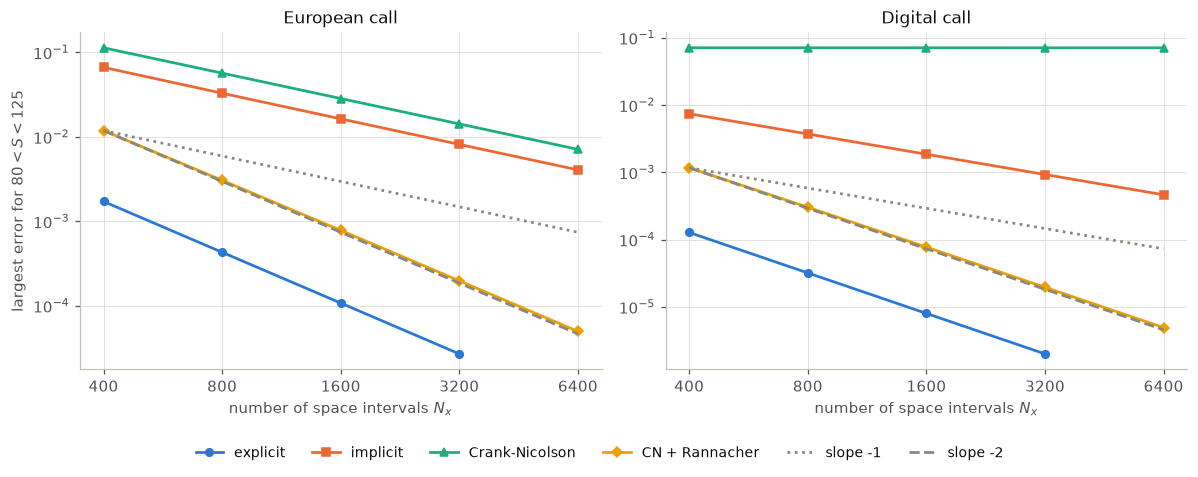

In [6]:
def window_error(option, S, V):
    exact = bs.call_price if option == "call" else bs.digital_price
    window = (S > 80) & (S < 125)
    return np.max(np.abs(V[window] - exact(S[window], K, r, sigma, T)))


methods = [("explicit", 0.0, 0), ("implicit", 1.0, 0), ("Crank-Nicolson", 0.5, 0), ("CN + Rannacher", 0.5, 2)]
n_x_values = np.array([400, 800, 1600, 3200, 6400])
tau_max = 0.5 * sigma**2 * T
errors = {}

for option in ["call", "digital"]:
    print(f"{option}: largest error for 80 < S < 125, and observed order between grids")
    for name, theta, n_r in methods:
        errs = []
        for n_x in n_x_values:
            if theta == 0.0:
                if n_x > 3200:
                    errs.append(np.nan)  # too many time steps to be worth running
                    continue
                dx = 4.0 / n_x
                n_tau = int(np.ceil(tau_max / (0.4 * dx**2)))
            else:
                n_tau = n_x // 40
            S, V = pde.price_heat_grid(option, K, r, sigma, T, 2.0, n_x, n_tau, theta, n_r)
            errs.append(window_error(option, S, V))
        errs = np.array(errs)
        errors[(option, name)] = errs
        orders = np.log2(errs[:-1] / errs[1:])
        print(f"  {name:15s} errors " + " ".join(f"{e:9.2e}" for e in errs) + "   orders " + " ".join(f"{o:5.2f}" for o in orders))
    print()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, option in zip(axes, ["call", "digital"]):
    for i, (name, theta, n_r) in enumerate(methods):
        ax.loglog(n_x_values, errors[(option, name)], marker=MARKERS[i], color=COLOURS[i], label=name)
    ref = errors[(option, "CN + Rannacher")][0]
    ax.loglog(n_x_values, ref * (n_x_values / n_x_values[0]) ** -1.0, ":", color=GREY, label="slope -1")
    ax.loglog(n_x_values, ref * (n_x_values / n_x_values[0]) ** -2.0, "--", color=GREY, label="slope -2")
    ax.set_xlabel("number of space intervals $N_x$")
    ax.set_title("European call" if option == "call" else "Digital call")
    ax.minorticks_off()
    ax.set_xticks(n_x_values, labels=[str(n) for n in n_x_values])
axes[0].set_ylabel("largest error for $80 < S < 125$")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=6)
fig.tight_layout()
fig.savefig("../figures/01_convergence.png")
plt.show()

The explicit scheme converges at second order in $\Delta x$, as expected since $\Delta\tau \propto \Delta x^2$, but its cost grows like $N_x^3$. The implicit scheme is stable with the large time steps, but its $O(\Delta\tau)$ error makes it first order in $N_x$. Plain Crank-Nicolson should be second order, but here it is only first order for the call, and for the digital its error does not decrease at all: it stays at about $0.07$ however fine the grid. With two Rannacher steps both options recover clean second order convergence. So the Crank-Nicolson failure is not a coding error, since the same code converges perfectly once its first two steps are made implicit. The next section looks at what is going on.

**Oscillations near the strike**

For a single Fourier mode the Crank-Nicolson amplification factor is

$$g = \frac{1 - 2\lambda\sin^2\left(\tfrac{1}{2}\xi\Delta x\right)}{1 + 2\lambda\sin^2\left(\tfrac{1}{2}\xi\Delta x\right)},$$

so $|g| \le 1$ for every $\lambda$ and the scheme is unconditionally stable. But for the sawtooth mode $g = (1 - 2\lambda)/(1 + 2\lambda)$, which tends to $-1$ as $\lambda$ grows. High frequency errors are therefore not damped. They just flip sign every step and decay very slowly. A smooth initial condition has almost no high frequency content, so this does not matter. The call payoff has a kink, though, and the digital payoff has a jump, and both put a lot of energy into exactly these modes. The implicit scheme has $g = 1/(1 + 4\lambda\sin^2(\frac{1}{2}\xi\Delta x))$, which is close to zero for the sawtooth when $\lambda$ is large, so a couple of implicit steps wipe out the high frequencies before Crank-Nicolson takes over. This is the same issue as stiffness in Module 3.4: the high frequency modes are the stiff components of the semi-discrete system, and Crank-Nicolson, although stable, does not damp them strongly. In the language of ODE solvers, it is A-stable but not L-stable. The cell below shows the effect directly on a grid with $N_x = 800$ and $N_\tau = 20$, so $\lambda = 40$.

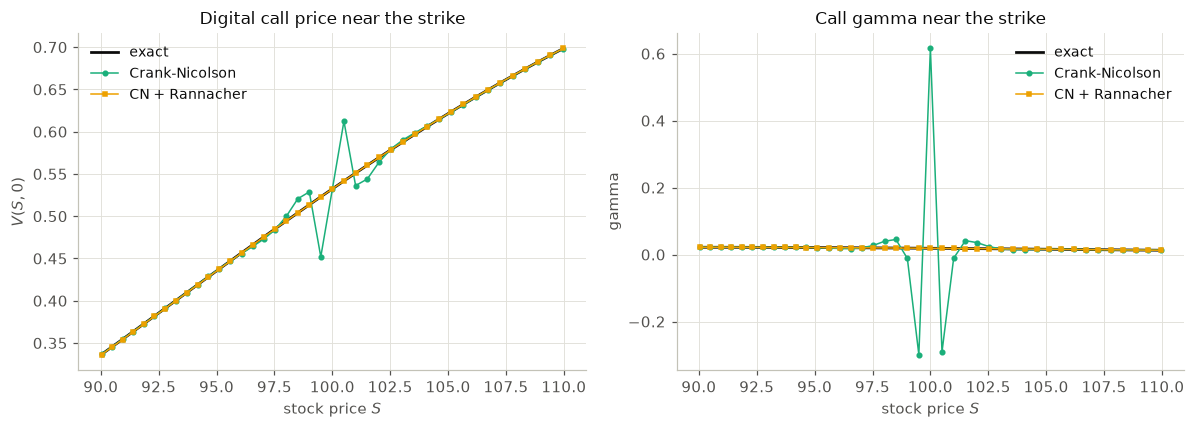

Largest digital price error, CN: 0.071
Largest call gamma error,   CN: 0.597


In [7]:
n_x, n_tau = 800, 20
S, V_cn = pde.price_heat_grid("digital", K, r, sigma, T, 2.0, n_x, n_tau, 0.5, n_rannacher=0)
S, V_ran = pde.price_heat_grid("digital", K, r, sigma, T, 2.0, n_x, n_tau, 0.5, n_rannacher=2)
S, C_cn = pde.price_heat_grid("call", K, r, sigma, T, 2.0, n_x, n_tau, 0.5, n_rannacher=0)
S, C_ran = pde.price_heat_grid("call", K, r, sigma, T, 2.0, n_x, n_tau, 0.5, n_rannacher=2)
S_in, _, gamma_cn = pde.grid_greeks(S, C_cn)
S_in, _, gamma_ran = pde.grid_greeks(S, C_ran)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
window = (S > 90) & (S < 110)
axes[0].plot(S[window], bs.digital_price(S[window], K, r, sigma, T), color=INK, label="exact")
axes[0].plot(S[window], V_cn[window], "o-", color=COLOURS[2], markersize=3, linewidth=1, label="Crank-Nicolson")
axes[0].plot(S[window], V_ran[window], "s-", color=COLOURS[3], markersize=3, linewidth=1, label="CN + Rannacher")
axes[0].set_title("Digital call price near the strike")
axes[0].set_xlabel("stock price $S$")
axes[0].set_ylabel("$V(S, 0)$")
axes[0].legend()

window_in = (S_in > 90) & (S_in < 110)
axes[1].plot(S_in[window_in], bs.call_gamma(S_in[window_in], K, r, sigma, T), color=INK, label="exact")
axes[1].plot(S_in[window_in], gamma_cn[window_in], "o-", color=COLOURS[2], markersize=3, linewidth=1, label="Crank-Nicolson")
axes[1].plot(S_in[window_in], gamma_ran[window_in], "s-", color=COLOURS[3], markersize=3, linewidth=1, label="CN + Rannacher")
axes[1].set_title("Call gamma near the strike")
axes[1].set_xlabel("stock price $S$")
axes[1].set_ylabel("gamma")
axes[1].legend()
fig.tight_layout()
fig.savefig("../figures/01_oscillations.png")
plt.show()

print(f"Largest digital price error, CN: {np.max(np.abs(V_cn - bs.digital_price(S, K, r, sigma, T))[window]):.3f}")
print(f"Largest call gamma error,   CN: {np.max(np.abs(gamma_cn - bs.call_gamma(S_in, K, r, sigma, T))[window_in]):.3f}")

The plain Crank-Nicolson digital price zigzags around the exact curve within a few grid points of the strike, with errors up to $0.07$. The call price looks fine to the eye, but its second derivative, gamma, oscillates wildly: the error at the strike is about $0.6$, around thirty times the true gamma of about $0.02$. This matches the convergence plot: the call's kink only produces errors of size $O(\Delta x)$ in the price, but differentiating twice turns them into $O(1/\Delta x)$ errors in gamma, which grow as the grid is refined. The jump in the digital produces $O(1)$ errors in the price itself. With two Rannacher steps both curves lie on the exact solution. This is also a numerical differentiation story (Section 1.3.5): small high frequency errors in a function become large errors in its derivatives.

**How many Rannacher steps are needed?**

Rannacher smoothing is usually described with two implicit steps (Pooley, Vetzal and Forsyth 2003), and the convergence plot shows that two are enough for the prices. Gamma is a harder test, because it is a second derivative and so amplifies any leftover high frequency error the most. Below we repeat the convergence study for the digital's gamma with 0, 2, 4 and 8 implicit start-up steps.

Digital gamma: largest error for 80 < S < 125
  0 start-up steps:  1.60e-01  6.33e-01  2.52e+00  1.01e+01  4.02e+01   worst point on finest grid S = 99.94
  2 start-up steps:  1.24e-04  1.10e-04  1.04e-04  1.01e-04  9.94e-05   worst point on finest grid S = 99.94
  4 start-up steps:  3.26e-05  8.23e-06  2.10e-06  5.33e-07  1.34e-07   worst point on finest grid S = 85.43
  8 start-up steps:  7.65e-05  1.79e-05  4.50e-06  1.13e-06  2.86e-07   worst point on finest grid S = 85.59

Largest |gamma| of the digital in the window: 7.12e-04


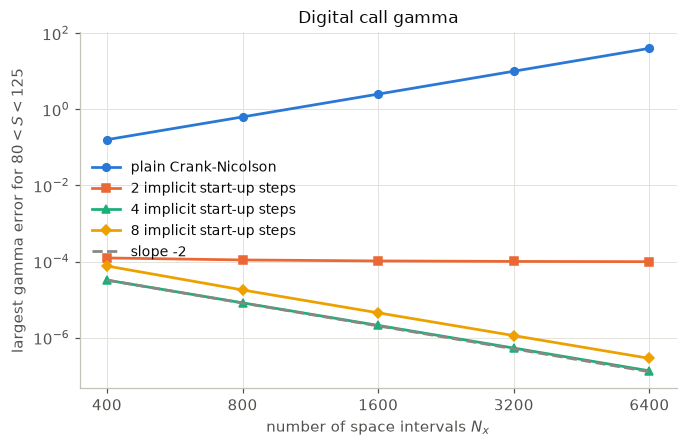

In [8]:
n_x_values = np.array([400, 800, 1600, 3200, 6400])
start_steps = [0, 2, 4, 8]
gamma_errors = {}

print("Digital gamma: largest error for 80 < S < 125")
for n_r in start_steps:
    errs = []
    for n_x in n_x_values:
        S, V = pde.price_heat_grid("digital", K, r, sigma, T, 2.0, n_x, n_x // 40, 0.5, n_r)
        S_in, delta, gamma = pde.grid_greeks(S, V)
        window = (S_in > 80) & (S_in < 125)
        err = np.abs(gamma[window] - bs.digital_gamma(S_in[window], K, r, sigma, T))
        errs.append(np.max(err))
        if n_x == 6400:
            worst_S = S_in[window][np.argmax(err)]
    gamma_errors[n_r] = np.array(errs)
    print(f"  {n_r} start-up steps: " + " ".join(f"{e:9.2e}" for e in errs) + f"   worst point on finest grid S = {worst_S:.2f}")

print()
print(f"Largest |gamma| of the digital in the window: {np.max(np.abs(bs.digital_gamma(S_in[window], K, r, sigma, T))):.2e}")

fig, ax = plt.subplots()
for i, n_r in enumerate(start_steps):
    label = "plain Crank-Nicolson" if n_r == 0 else f"{n_r} implicit start-up steps"
    ax.loglog(n_x_values, gamma_errors[n_r], marker=MARKERS[i], color=COLOURS[i], label=label)
ref = gamma_errors[4][0]
ax.loglog(n_x_values, ref * (n_x_values / n_x_values[0]) ** -2.0, "--", color=GREY, label="slope -2")
ax.set_xlabel("number of space intervals $N_x$")
ax.set_ylabel("largest gamma error for $80 < S < 125$")
ax.set_title("Digital call gamma")
ax.minorticks_off()
ax.set_xticks(n_x_values, labels=[str(n) for n in n_x_values])
ax.legend(loc="center left")
fig.savefig("../figures/01_rannacher_steps.png")
plt.show()

Without smoothing the gamma error grows rapidly with refinement. With two start-up steps it stops improving at about $10^{-4}$, which is around 15% of the largest gamma, and the worst point sits right next to the strike. With four or more steps the error falls at second order again. Two implicit steps damp the highest frequency modes, but the jump in the digital also feeds slightly lower frequencies that two steps do not damp enough, and gamma is sensitive enough to see them. Giles and Carter (2006) give a careful analysis of Rannacher start-up for non-smooth payoffs. Our practical conclusion is that the number of start-up steps should be chosen with the least smooth quantity we need in mind, not just the price. Using eight steps costs a little accuracy on coarse grids, because each implicit step adds an $O(\Delta\tau^2)$ local error, but it does not change the order.

**Greeks from the grid and the chain rule**

The Greeks delta $= \partial V/\partial S$ and gamma $= \partial^2V/\partial S^2$ measure how the option value responds to the stock price, and traders need them as much as the price. Our grid is uniform in $x = \ln(S/K)$, not in $S$, so central differences on the grid give $V_x$ and $V_{xx}$, not the derivatives we want. Since $\partial x/\partial S = 1/S$, the chain rule gives

$$\Delta = \frac{1}{S}V_x, \qquad \Gamma = \frac{1}{S^2}\left(V_{xx} - V_x\right),$$

which are the same identities we used in the transform. The $-V_x$ term in gamma is easy to forget. The cell below compares the correct formula with the naive $V_{xx}/S^2$ for the call.

Largest gamma error, correct chain rule:  1.11e-06
Largest gamma error, naive V_xx / S^2:    7.47e-03
Largest delta error, V_x / S:             8.37e-06


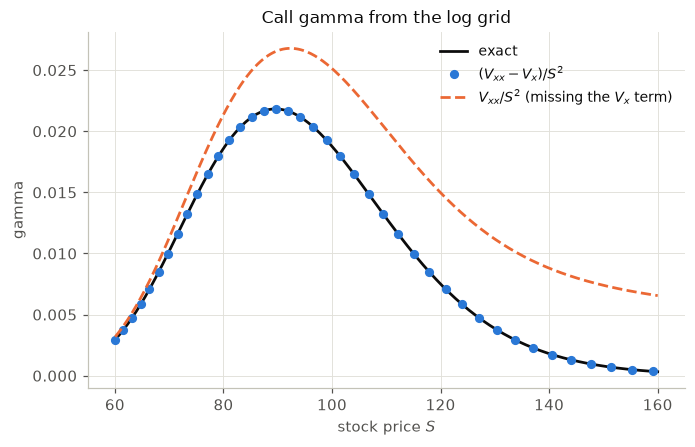

In [9]:
S, V = pde.price_heat_grid("call", K, r, sigma, T, 2.0, 1600, 160, 0.5, n_rannacher=2)
dx = np.log(S[1] / S[0])
V_x = (V[2:] - V[:-2]) / (2 * dx)
V_xx = (V[2:] - 2 * V[1:-1] + V[:-2]) / dx**2
S_in = S[1:-1]
gamma_correct = (V_xx - V_x) / S_in**2
gamma_naive = V_xx / S_in**2
gamma_exact = bs.call_gamma(S_in, K, r, sigma, T)

window = (S_in > 60) & (S_in < 160)
print(f"Largest gamma error, correct chain rule:  {np.max(np.abs(gamma_correct - gamma_exact)[window]):.2e}")
print(f"Largest gamma error, naive V_xx / S^2:    {np.max(np.abs(gamma_naive - gamma_exact)[window]):.2e}")

delta_exact = bs.call_delta(S_in, K, r, sigma, T)
print(f"Largest delta error, V_x / S:             {np.max(np.abs(V_x / S_in - delta_exact)[window]):.2e}")

fig, ax = plt.subplots()
ax.plot(S_in[window], gamma_exact[window], color=INK, label="exact")
ax.plot(S_in[window][::10], gamma_correct[window][::10], "o", color=COLOURS[0], label=r"$(V_{xx} - V_x)/S^2$")
ax.plot(S_in[window], gamma_naive[window], "--", color=COLOURS[1], label=r"$V_{xx}/S^2$ (missing the $V_x$ term)")
ax.set_xlabel("stock price $S$")
ax.set_ylabel("gamma")
ax.set_title("Call gamma from the log grid")
ax.legend()
fig.savefig("../figures/01_gamma_chain_rule.png")
plt.show()

With the chain rule done properly the grid gamma agrees with the closed form to about $10^{-6}$, compared with a peak gamma of about $0.022$. The naive version is wrong by exactly $V_x/S^2 = \Delta/S$, which is a modelling mistake rather than a discretisation error, so it does not shrink as the grid is refined. Delta needs no correction term and is accurate to about $10^{-5}$.

**Discussion**

The heat equation transform turns the Black-Scholes PDE into the simplest parabolic PDE there is. This let us reuse the theory and code of R4.1(a) directly, and it makes the explicit stability limit $\lambda \le \frac{1}{2}$ independent of how far the grid extends, unlike the original $S$ variable, where the limit shrinks like $1/S_{\max}^2$. Among the schemes, explicit Euler is simple and accurate when it is stable, but its stability limit forces $\Delta\tau \propto \Delta x^2$ and a cost that grows like $N_x^3$. Implicit Euler is robust but only first order in time. Crank-Nicolson is second order and unconditionally stable, but with the large time steps that make it attractive it fails to damp the high frequency errors created by a non-smooth payoff. For the call this costs an order of convergence in the price and destroys gamma; for the digital the price itself stops converging. Rannacher smoothing fixes this at almost no cost, and we found that the number of implicit start-up steps matters for the digital's gamma, where two steps were not enough and four were.

There are some limitations. The grid is uniform, while practical codes concentrate points near the strike. The transform only works for constant $r$ and $\sigma$. And we only treated European options, where the exact answer is known. The real value of a PDE solver is for products without closed forms, such as American options, where the comparison against exact answers made here is what would give us confidence in the code.